# Module 10 — A Bridge to Machine Learning: Introduction to scikit-learn

**Python for Machine Learning · MSc Artificial Intelligence · Swansea University**

---

## Learning objectives

1. Describe the standard supervised-learning workflow.
2. Use scikit-learn's consistent **estimator API**: `fit`, `predict`, `transform`, `score`.
3. Split data correctly with `train_test_split` and evaluate with appropriate **metrics**.
4. Pre-process data with scalers, encoders and imputers inside a **Pipeline** and **ColumnTransformer**, avoiding data leakage.
5. Use **cross-validation** and **grid search** to compare models and tune hyper-parameters.
6. Recognise **under-fitting** and **over-fitting**.

This module is an *introduction to the tools*. The theory behind each model is the subject of the Machine Learning course itself.

---

## 10.1 The supervised learning workflow

```text
 1. Define the problem     -> what is X (features), what is y (target)? classification or regression?
 2. Load & explore data    -> pandas, matplotlib              (Modules 8-9)
 3. Split                  -> train / test (and validation, or cross-validation)
 4. Pre-process            -> impute, scale, encode  -- fitted on TRAIN only
 5. Train                  -> model.fit(X_train, y_train)
 6. Evaluate               -> metrics on the TEST set, which the model never saw
 7. Iterate                -> features, models, hyper-parameters (via cross-validation)
```

* **Classification:** `y` is a category (spam / not spam, digit 0–9).
* **Regression:** `y` is a continuous number (price, exam score).

## 10.2 The estimator API

Every scikit-learn object follows the same interface — the design you implemented yourself in Module 6:

| Method | Who has it | What it does |
|---|---|---|
| `Estimator(**hyperparams)` | all | create the object with hyper-parameters |
| `.fit(X, y)` | all | learn from data; learned attributes end with `_` |
| `.predict(X)` | models | predictions for new data |
| `.predict_proba(X)` | most classifiers | class probabilities |
| `.score(X, y)` | models | default metric (accuracy / $R^2$) |
| `.transform(X)` / `.fit_transform(X)` | transformers (scalers, encoders) | change the data |

`X` is 2-D, shape `(n_samples, n_features)`; `y` is 1-D, shape `(n_samples,)`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(sklearn.__version__)

1.9.1


## 10.3 A first classifier: the Iris dataset

scikit-learn includes small classic datasets. Iris: 150 flowers, 4 measurements, 3 species.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print(X.shape, y.shape)
print(iris.target_names)
X.head()

(150, 4) (150,)
['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Train / test split

We hold out data the model never sees during training, to estimate how it performs on **new** data. `stratify=y` keeps class proportions equal in both parts; `random_state` makes the split reproducible.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(np.bincount(y_train), np.bincount(y_test))

(112, 4) (38, 4)
[38 37 37] [12 13 13]


### Fit, predict, evaluate

In [4]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)   # 1. choose model + hyper-parameters
knn.fit(X_train, y_train)                   # 2. learn
y_pred = knn.predict(X_test)                # 3. predict
print(y_pred[:10])
print("test accuracy:", knn.score(X_test, y_test))

[0 1 1 1 0 1 2 2 2 2]
test accuracy: 0.9736842105263158


Swapping models changes **one line** — that's the power of a common interface:

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=0),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:<20} test accuracy = {model.score(X_test, y_test):.3f}")

kNN                  test accuracy = 0.974


Logistic regression  test accuracy = 0.947
Decision tree        test accuracy = 0.921


Random forest        test accuracy = 0.895


Learned parameters are available as attributes ending in `_`:

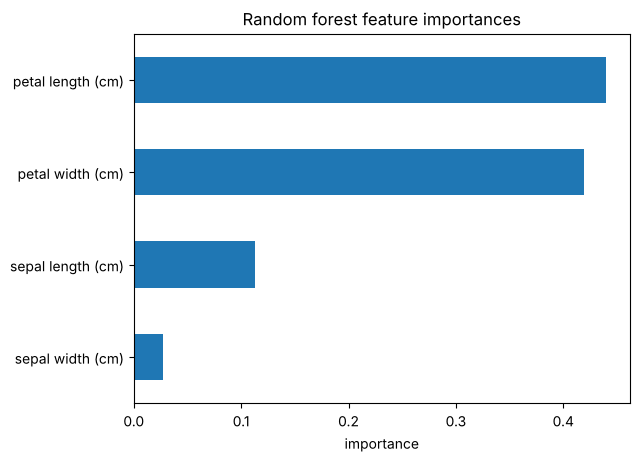

[[-0.54  0.83 -2.26 -0.97]
 [ 0.46 -0.44 -0.17 -0.82]
 [ 0.08 -0.39  2.43  1.8 ]]
[[0.987 0.013 0.   ]
 [0.006 0.662 0.333]
 [0.027 0.919 0.054]]


In [6]:
rf = models["Random forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
ax = importances.plot(kind="barh", title="Random forest feature importances")
ax.set_xlabel("importance")
plt.show()

print(models["Logistic regression"].coef_.round(2))
print(models["Logistic regression"].predict_proba(X_test.iloc[:3]).round(3))

## 10.4 Classification metrics

Accuracy alone can mislead, especially with **imbalanced** classes (if 95 % of e-mails are not spam, always predicting "not spam" gives 95 % accuracy!). For a binary problem with positive class 1:

* **Precision** $= \frac{TP}{TP + FP}$ — of the predicted positives, how many are right?
* **Recall** $= \frac{TP}{TP + FN}$ — of the actual positives, how many did we find?
* **F1** — the harmonic mean of precision and recall.

Recall the exercise from Module 3 — scikit-learn gives the same numbers:

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_true = [1, 0, 1, 1, 0, 1, 0, 0, 1, 1]
y_hat  = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]
print("accuracy ", accuracy_score(y_true, y_hat))
print("precision", precision_score(y_true, y_hat))
print("recall   ", round(recall_score(y_true, y_hat), 3))
print("f1       ", round(f1_score(y_true, y_hat), 3))
print(confusion_matrix(y_true, y_hat))     # rows = true, columns = predicted: [[TN, FP], [FN, TP]]

accuracy  0.7
precision 0.8
recall    0.667
f1        0.727
[[3 1]
 [2 4]]


A real binary task — the breast-cancer dataset (malignant vs benign tumours):

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score

cancer = load_breast_cancer()
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.25, random_state=0, stratify=cancer.target
)
clf = RandomForestClassifier(n_estimators=300, random_state=0).fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)
print(classification_report(yc_test, yc_pred, target_names=cancer.target_names))
print("ROC AUC:", round(roc_auc_score(yc_test, clf.predict_proba(Xc_test)[:, 1]), 4))

              precision    recall  f1-score   support

   malignant       0.92      0.92      0.92        53
      benign       0.96      0.96      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143

ROC AUC: 0.9769


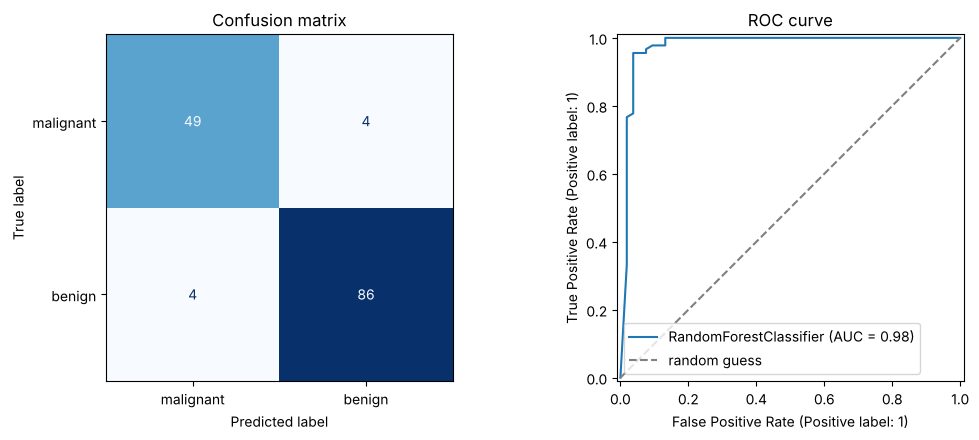

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, display_labels=cancer.target_names,
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
axes[0].grid(False)
RocCurveDisplay.from_estimator(clf, Xc_test, yc_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guess")
axes[1].set_title("ROC curve")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10.5 Regression

Predict the (continuous) exam score of our MSc students from their study behaviour.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

students = pd.read_csv("../data/student_performance.csv").drop_duplicates().dropna()
features = ["hours_studied", "attendance_pct", "prior_gpa"]
Xs, ys = students[features], students["exam_score"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.2, random_state=1)

reg = LinearRegression().fit(Xs_train, ys_train)
ys_pred = reg.predict(Xs_test)

print("coefficients:", dict(zip(features, reg.coef_.round(3))), "intercept:", round(reg.intercept_, 3))
print(f"MAE  = {mean_absolute_error(ys_test, ys_pred):.2f} marks")
print(f"RMSE = {np.sqrt(mean_squared_error(ys_test, ys_pred)):.2f} marks")
print(f"R^2  = {r2_score(ys_test, ys_pred):.3f}")

coefficients: {'hours_studied': np.float64(1.512), 'attendance_pct': np.float64(0.313), 'prior_gpa': np.float64(6.34)} intercept: -14.383
MAE  = 7.50 marks
RMSE = 10.19 marks
R^2  = 0.552


Interpretation: each extra weekly study hour is associated with roughly `coef_[0]` extra exam marks, *holding the other features constant*.

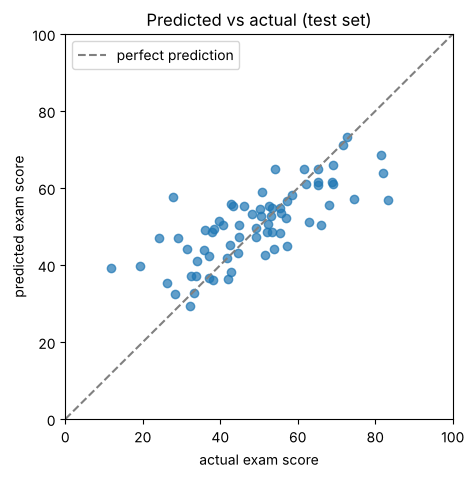

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(ys_test, ys_pred, alpha=0.7)
lims = [0, 100]
ax.plot(lims, lims, linestyle="--", color="gray", label="perfect prediction")
ax.set(xlabel="actual exam score", ylabel="predicted exam score", xlim=lims, ylim=lims,
       title="Predicted vs actual (test set)")
ax.legend()
plt.show()

## 10.6 Pre-processing and data leakage

Many models (kNN, SVM, logistic regression, neural networks) are sensitive to the **scale** of the features. Scalers are *transformers*:

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xc_train_s = scaler.fit_transform(Xc_train)   # learn mean/std on TRAIN, then transform it
Xc_test_s = scaler.transform(Xc_test)         # apply the SAME mean/std to TEST - never refit!
print(Xc_train_s.mean(axis=0)[:3].round(3), Xc_train_s.std(axis=0)[:3].round(3))

for name, (tr, te) in {"raw": (Xc_train, Xc_test), "scaled": (Xc_train_s, Xc_test_s)}.items():
    acc = KNeighborsClassifier().fit(tr, yc_train).score(te, yc_test)
    print(f"kNN on {name} features: {acc:.3f}")

[-0.  0.  0.] [1. 1. 1.]
kNN on raw features: 0.916
kNN on scaled features: 0.951


> **Data leakage** happens when information from the test set influences training — e.g. fitting a scaler or imputer on the full dataset before splitting. Results then look better than they will be in reality. The cure is the **Pipeline**.

### Pipelines

A `Pipeline` chains transformers and a final model into **one estimator**. Calling `fit` fits every step on the training data only; `predict` applies the same transformations to new data.

In [13]:
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
pipe.fit(Xc_train, yc_train)
print("pipeline test accuracy:", round(pipe.score(Xc_test, yc_test), 4))
print(pipe)

pipeline test accuracy: 0.958
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=5000))])


### Mixed column types: `ColumnTransformer`

Real tables mix numeric and categorical columns, often with missing values. A `ColumnTransformer` applies different pre-processing to different columns:

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

raw = pd.read_csv("../data/student_performance.csv").drop_duplicates()
raw["study_mode"] = raw["study_mode"].str.strip().str.capitalize()

numeric = ["hours_studied", "attendance_pct", "prior_gpa", "age"]
categorical = ["programme", "study_mode"]
X_all, y_all = raw[numeric + categorical], raw["passed"]
# note: exam/assignment scores are NOT used - they determine 'passed' (target leakage)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=0, stratify=y_all
)
model.fit(Xa_train, ya_train)
print("test accuracy:", round(model.score(Xa_test, ya_test), 3))
print("baseline (always predict 'passed'):", round(ya_test.mean(), 3))

test accuracy: 0.77
baseline (always predict 'passed'): 0.72


Always compare to a simple **baseline**. Here the model must beat the majority-class rate to be useful.

In [15]:
model.named_steps["prep"].get_feature_names_out()

array(['num__hours_studied', 'num__attendance_pct', 'num__prior_gpa',
       'num__age', 'cat__programme_MSc AI',
       'cat__programme_MSc Computer Science',
       'cat__programme_MSc Data Science', 'cat__study_mode_Full-time',
       'cat__study_mode_Part-time'], dtype=object)

## 10.7 Cross-validation

A single train/test split is noisy: a different random split gives a different score. **k-fold cross-validation** splits the training data into *k* folds, trains on *k − 1* and validates on the remaining one, *k* times, and averages:

```text
fold 1: [VAL][train][train][train][train]
fold 2: [train][VAL][train][train][train]
 ...
fold 5: [train][train][train][train][VAL]
```

In [16]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, Xa_train, ya_train, cv=5, scoring="accuracy")
print(scores.round(3))
print(f"mean = {scores.mean():.3f} ± {scores.std():.3f}")

[0.8   0.85  0.833 0.733 0.867]
mean = 0.817 ± 0.047


Comparing several models fairly, with the same folds:

In [17]:
candidates = {
    "LogReg": LogisticRegression(max_iter=1000),
    "kNN": KNeighborsClassifier(n_neighbors=15),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=0),
}
for name, clf_ in candidates.items():
    pipe_ = Pipeline([("prep", preprocess), ("clf", clf_)])
    s = cross_val_score(pipe_, Xa_train, ya_train, cv=5)
    print(f"{name:<13} {s.mean():.3f} ± {s.std():.3f}")

LogReg        0.817 ± 0.047


kNN           0.773 ± 0.008


RandomForest  0.777 ± 0.040


## 10.8 Hyper-parameter tuning with grid search

**Parameters** are learned by `fit` (e.g. regression coefficients). **Hyper-parameters** are chosen by you before training (e.g. `n_neighbors`, `max_depth`). `GridSearchCV` tries every combination with cross-validation. Inside a pipeline, parameter names use `step__parameter`:

In [18]:
from sklearn.model_selection import GridSearchCV

pipe_knn = Pipeline([("prep", preprocess), ("clf", KNeighborsClassifier())])
param_grid = {
    "clf__n_neighbors": [3, 5, 11, 21, 41],
    "clf__weights": ["uniform", "distance"],
}
search = GridSearchCV(pipe_knn, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
search.fit(Xa_train, ya_train)

print("best params:", search.best_params_)
print("best CV accuracy:", round(search.best_score_, 3))
print("test accuracy of the best model:", round(search.score(Xa_test, ya_test), 3))

best params: {'clf__n_neighbors': 41, 'clf__weights': 'distance'}
best CV accuracy: 0.777
test accuracy of the best model: 0.8


In [19]:
results = pd.DataFrame(search.cv_results_)
results[["param_clf__n_neighbors", "param_clf__weights", "mean_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head()

,param_clf__n_neighbors,param_clf__weights,mean_test_score,rank_test_score
9,41,distance,0.776667,1
6,21,uniform,0.770000,2
7,21,distance,0.770000,2
4,11,uniform,0.766667,4
8,41,uniform,0.763333,5


> The test set is used **once**, at the very end. If you use it to choose hyper-parameters, it is no longer an unbiased estimate of performance.

## 10.9 Under-fitting and over-fitting

Model complexity controls the trade-off. A decision tree's `max_depth` is a good illustration: too shallow → **under-fits** (poor on both sets); too deep → **over-fits** (memorises training data, worse on validation).

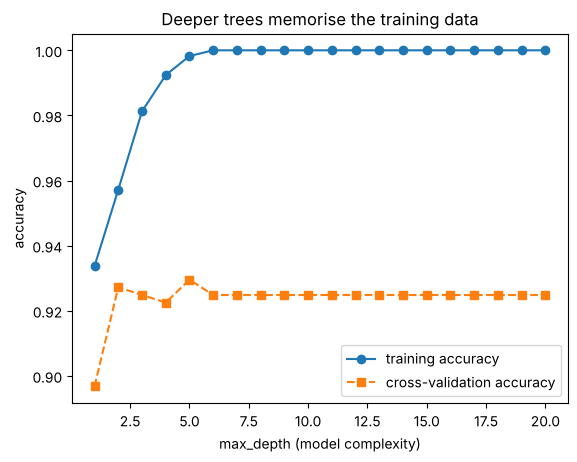

In [20]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 21)
train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=0), Xc_train, yc_train,
    param_name="max_depth", param_range=depths, cv=5,
)

fig, ax = plt.subplots()
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training accuracy")
ax.plot(depths, val_scores.mean(axis=1), marker="s", linestyle="--", label="cross-validation accuracy")
ax.set(xlabel="max_depth (model complexity)", ylabel="accuracy",
       title="Deeper trees memorise the training data")
ax.legend()
plt.show()

## 10.10 Saving and loading a model

In [21]:
import joblib

joblib.dump(search.best_estimator_, "student_pass_model.joblib")
loaded = joblib.load("student_pass_model.joblib")

new_student = pd.DataFrame([{
    "hours_studied": 18, "attendance_pct": 90, "prior_gpa": 3.4, "age": 24,
    "programme": "MSc AI", "study_mode": "Full-time",
}])
print("prediction:", loaded.predict(new_student), "P(pass):", loaded.predict_proba(new_student)[:, 1].round(3))

prediction: [1] P(pass): [0.919]


Because the whole pipeline is saved, the new data only needs the raw columns; imputation, scaling and encoding are applied automatically.

## 10.11 Where to go next

* scikit-learn user guide: <https://scikit-learn.org/stable/user_guide.html>
* Deep learning: **PyTorch** (`torch.Tensor` behaves much like a NumPy array; models are classes with `__init__` and `forward` — Module 6!).
* Habits that matter: set random seeds, keep a test set untouched, use pipelines, compare to baselines, plot everything.

---

## Summary

* Workflow: split → pre-process (fit on train) → fit → evaluate on test.
* All estimators share `fit` / `predict` / `score`; transformers share `fit` / `transform`.
* Choose metrics for the problem: precision, recall, F1, ROC AUC for classification; MAE, RMSE, $R^2$ for regression.
* `Pipeline` + `ColumnTransformer` prevent leakage and keep pre-processing and model together.
* Use cross-validation and `GridSearchCV` to compare and tune; touch the test set once.

---

## Exercises

Solutions: `solutions/10_intro_scikit_learn_solutions.ipynb`.

**Exercise 10.1 — Wine classification.**
Load `sklearn.datasets.load_wine()`. (a) How many samples, features and classes are there, and how many samples per class? (b) Split 70/30 with stratification and `random_state=0`. (c) Train a `KNeighborsClassifier` **with and without** a `StandardScaler` (use a pipeline) and compare test accuracies. Why is the difference so large? (Hint: look at `X.describe()`.)

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Your code here

**Exercise 10.2 — Choosing k.**
Using the scaled kNN pipeline on the wine training set, compute the 5-fold cross-validation accuracy for `n_neighbors` from 1 to 30. Plot mean CV accuracy against k and report the best k. Then evaluate that model **once** on the test set.

In [23]:
# Your code here

**Exercise 10.3 — Metrics for imbalanced data.**
Create an imbalanced dataset with `make_classification(n_samples=2000, weights=[0.95, 0.05], random_state=0)`. (a) Train a `DummyClassifier(strategy="most_frequent")` and a `LogisticRegression`. (b) For both, print accuracy, precision, recall and F1 for the positive class. (c) Explain in a comment why accuracy is misleading here.

In [24]:
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
# Your code here

**Exercise 10.4 — Regression on the student data.**
Predict `exam_score` from `hours_studied`, `attendance_pct`, `prior_gpa`, `age`, `programme` and `study_mode`. Build a pipeline with imputation, scaling and one-hot encoding, and compare `LinearRegression` and `RandomForestRegressor` using 5-fold cross-validated **RMSE** (`scoring="neg_root_mean_squared_error"` — note the sign!). Which model would you choose and why?

In [25]:
# Your code here

**Exercise 10.5 — Spot the leakage.**
The code below reports an impressive accuracy. Identify **two** sources of data leakage, explain them in comments, and write a corrected version using a pipeline.

In [26]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X, y = load_breast_cancer(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)                  # (1)
X_tr, X_te, y_tr, y_te = train_test_split(X_scaled, y, random_state=0)

best_C, best_acc = None, 0
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    acc = LogisticRegression(C=C, max_iter=5000).fit(X_tr, y_tr).score(X_te, y_te)   # (2)
    if acc > best_acc:
        best_C, best_acc = C, acc
print("best C:", best_C, "accuracy:", best_acc)

best C: 0.1 accuracy: 0.965034965034965


**Exercise 10.6 — Mini project (challenge).**
Build the best model you can to predict `passed` for the student dataset **without** using `exam_score` or `assignment_score`.
1. Load and clean the data (Module 8).
2. Split into train/test (stratified, 25 % test).
3. Build a `ColumnTransformer` + model pipeline.
4. Use `GridSearchCV` to tune **at least two** model types (hint: `param_grid` can be a list of dicts, each with its own `"clf": [Model()]` entry).
5. Report the best CV score, the test accuracy, the classification report, and plot the confusion matrix.
6. Write 3–4 sentences interpreting the results: which features matter? How much better than the baseline is it?

In [27]:
# Your code here